<center>
<img src="img/logo-hds.png" width="650"/>

***

<center>Lecture 4</center>

***

<center>Signal Quality, Sampling, Filtering, Segmentation & Preprocessing</center>  

***

<center>28 September 2026<center>
<center>Rahman Peimankar<center>

## From Lecture 3 to Lecture 4

In Lecture 3 we learned to:

- load real WFDB records;
- inspect channels, units, sampling rate, and metadata;
- plot physiological signals and annotations;
- calculate RR intervals and simple record summaries.

**Now the next question is:**  
> Can we trust the signal we loaded, and how should we prepare it before extracting features?

## Learning outcomes

By the end of today you should be able to:

1. recognise common physiological-signal artefacts;
2. explain sampling frequency, Nyquist frequency, and aliasing;
3. apply simple high-pass, low-pass, band-pass, and notch filters;
4. resample a signal safely;
5. segment signals into fixed, overlapping, or event-centred windows;
6. build a small reproducible preprocessing pipeline.

## Today's preprocessing pipeline

**Raw signal**

↓ inspect metadata and quality

**Identify artefacts**

↓ choose appropriate sampling / resampling

**Filter only when justified**

↓ create analysis windows

**Quality-check each window**

↓

**Cleaned segments → Lecture 5 feature extraction**

The preprocessing depends on the downstream task: morphology, rhythm, activity, sleep, etc.

## Setup: libraries we will reuse

We continue with **WFDB** and add **SciPy Signal**.

- `wfdb` — stream PhysioNet records
- `numpy` — numerical arrays
- `pandas` — quality tables
- `matplotlib` — visualization
- `scipy.signal` — filters and resampling

In [1]:
# Run once if needed:
# %pip install wfdb scipy pandas matplotlib numpy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from scipy.signal import (
    butter, sosfiltfilt, filtfilt,
    iirnotch, resample_poly
)

plt.rcParams["figure.figsize"] = (12, 4)

## What does “signal quality” mean?

A high-quality biosignal is **fit for the intended analysis**.

For example:

- ECG rhythm analysis needs identifiable QRS complexes;
- PPG pulse-rate estimation needs clear pulsatile peaks;
- accelerometry may intentionally contain rapid movement.

So signal quality is **not one universal number**.

### First rule
**Always inspect the waveform before trusting a metric.**

## Common artefacts in physiological signals

| Problem | Typical appearance | Common cause |
|---|---|---|
| Baseline wander | slow drifting baseline | breathing, posture, electrodes |
| High-frequency noise | rough / fuzzy waveform | muscle activity, electronics |
| Motion artefact | abrupt irregular deflections | movement, poor contact |
| Mains interference | periodic 50/60 Hz component | electrical environment |
| Flat signal | little/no variation | detached or failed sensor |
| Saturation / clipping | flattened peaks at limits | sensor / ADC range |
| Missing samples | gaps / NaNs | transmission or recording failure |

**Different artefacts require different responses.**

## A real noisy ECG dataset

We will use the **MIT-BIH Noise Stress Test Database (`nstdb`)**.

It includes ambulatory ECG contaminated with:

- baseline wander (`bw`);
- muscle artefact (`ma`);
- electrode-motion artefact (`em`);
- noisy versions of MIT-BIH records such as `118e00`.


**Dataset:** PhysioNet, open access.

## Load matching clean and noisy ECG

Noise in the stress-test records begins after the first 5 minutes.

We therefore compare the same time interval from:

- clean MIT-BIH record `118`;
- noisy NSTDB record `118e00`.

In [3]:
start_s = 305
duration_s = 20

hdr = wfdb.rdheader("118e00", pn_dir="nstdb")
fs = hdr.fs

sampfrom = int(start_s * fs)
sampto = int((start_s + duration_s) * fs)

clean = wfdb.rdrecord(
    "118", pn_dir="mitdb",
    sampfrom=sampfrom, sampto=sampto
)

noisy = wfdb.rdrecord(
    "118e00", pn_dir="nstdb",
    sampfrom=sampfrom, sampto=sampto
)

print("Sampling frequency:", fs, "Hz")
print("Channels:", noisy.sig_name)

Sampling frequency: 360 Hz
Channels: ['MLII', 'V1']


## Visual comparison: clean vs noisy

Plot the **same lead** and the **same time interval**.

Ask:

- Can I still identify beats?
- Is the baseline stable?
- Are sharp artefacts larger than the ECG?
- Would a simple filter solve the problem?

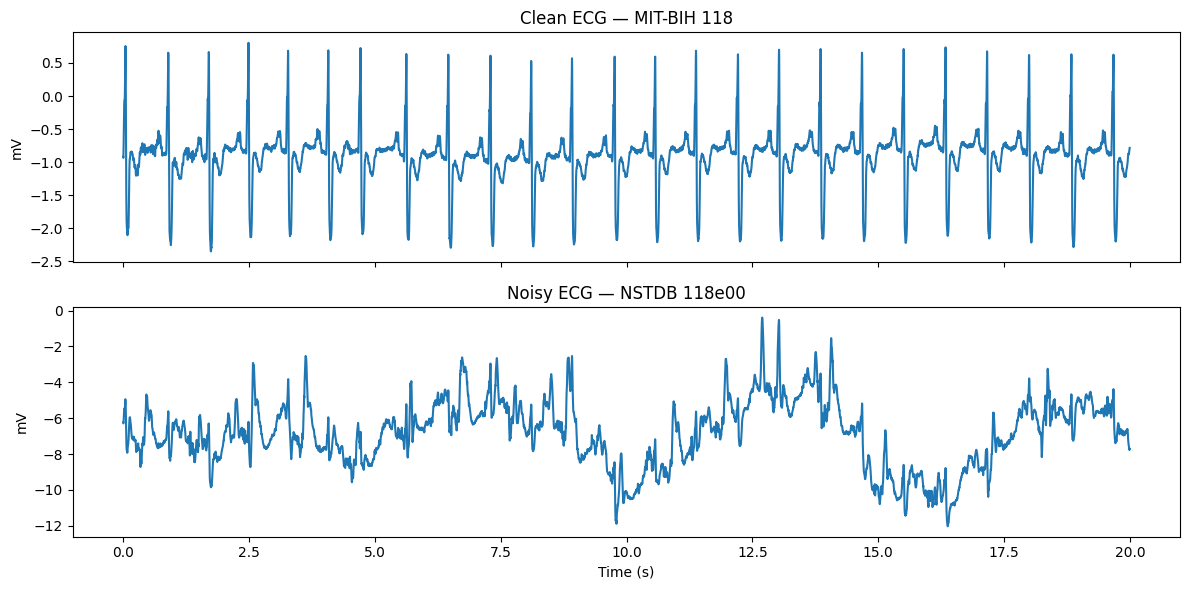

In [4]:
t = np.arange(noisy.sig_len) / fs
lead = 0

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

ax[0].plot(t, clean.p_signal[:, lead])
ax[0].set_title("Clean ECG — MIT-BIH 118")
ax[0].set_ylabel(clean.units[lead])

ax[1].plot(t, noisy.p_signal[:, lead])
ax[1].set_title("Noisy ECG — NSTDB 118e00")
ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel(noisy.units[lead])

plt.tight_layout()
plt.show()

## Look at three real artefact recordings

NSTDB also provides noise-only records:

- `bw` — baseline wander;
- `ma` — muscle artefact;
- `em` — electrode motion.

These are useful because the artefacts are **real recordings**, not idealized mathematical noise.

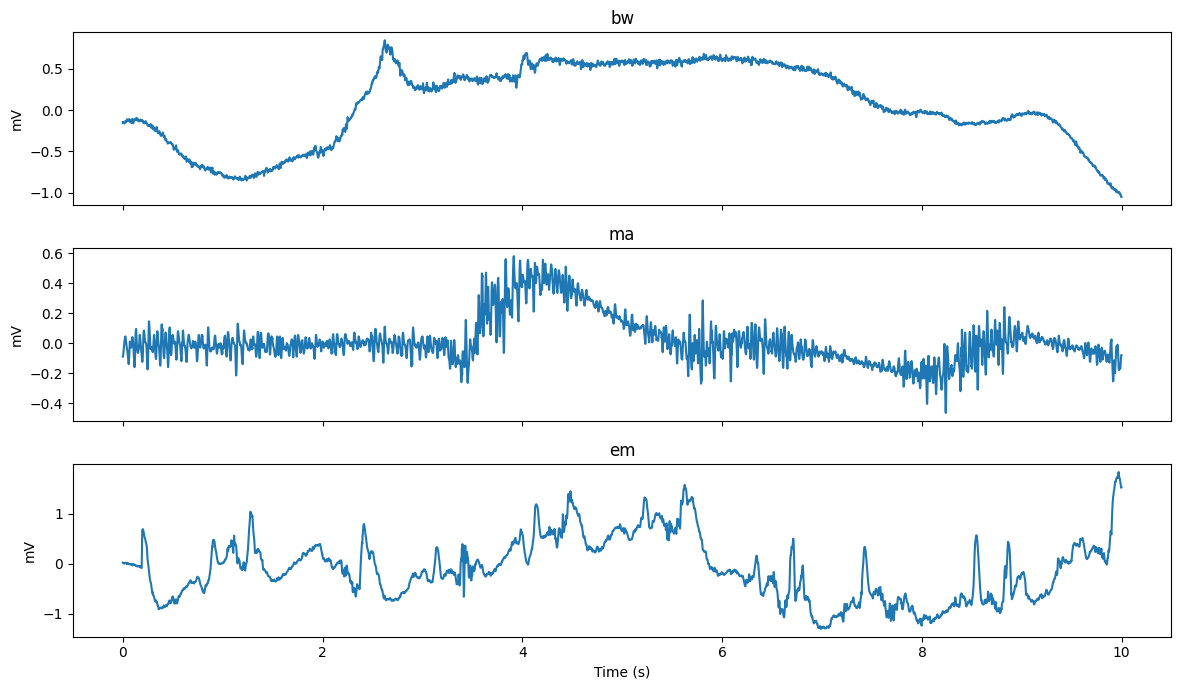

In [5]:
noise_records = ["bw", "ma", "em"]

fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

for i, rec_name in enumerate(noise_records):
    rec = wfdb.rdrecord(
        rec_name, pn_dir="nstdb",
        sampfrom=0, sampto=int(10 * fs)
    )
    tt = np.arange(rec.sig_len) / rec.fs
    ax[i].plot(tt, rec.p_signal[:, 0])
    ax[i].set_title(rec_name)
    ax[i].set_ylabel(rec.units[0])

ax[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

## Some problems are not “filtering problems”

### Flatline
Sensor detached, lead failure, or lost contact.

### Missing samples
Data transmission or recording gap.

### Clipping / saturation
The true amplitude exceeds the measurable range.

A filter cannot recreate information that was never recorded.

**Possible actions:**

- reject the segment;
- flag it;
- impute only when scientifically justified;
- use another channel/modalitiy if available.

## Simple quality metrics: useful, but only as clues

For a segment we can calculate:

- missing-value fraction;
- standard deviation;
- peak-to-peak range;
- fraction of almost-flat consecutive samples;
- RMS of the first difference as a rough “rapid-change” measure.

These are **heuristics**, not universal physiological quality scores.

Compare values only when signal type, units, and acquisition are comparable.

In [6]:
def basic_quality_metrics(x, flat_eps=1e-6):
    x = np.asarray(x, dtype=float)
    finite = np.isfinite(x)
    xf = x[finite]

    if len(xf) < 2:
        return {
            "missing_fraction": 1 - finite.mean(),
            "std": np.nan,
            "peak_to_peak": np.nan,
            "flat_fraction": np.nan,
            "derivative_rms": np.nan,
        }

    dx = np.diff(xf)

    return {
        "missing_fraction": 1 - finite.mean(),
        "std": np.std(xf),
        "peak_to_peak": np.ptp(xf),
        "flat_fraction": np.mean(np.abs(dx) < flat_eps),
        "derivative_rms": np.sqrt(np.mean(dx**2)),
    }

pd.DataFrame({
    "clean": basic_quality_metrics(clean.p_signal[:, 0]),
    "noisy": basic_quality_metrics(noisy.p_signal[:, 0]),
}).T

,missing_fraction,std,peak_to_peak,flat_fraction,derivative_rms
clean,0.0,0.416769,3.155,0.110849,0.072978
noisy,0.0,1.839158,11.630,0.026531,0.126749


## Quality can change within one recording

A 30-minute or 24-hour recording may contain both:

- excellent segments;
- motion-contaminated segments;
- missing / disconnected periods.

So quality assessment is often performed **window by window** rather than once per subject.

This also prepares the data for later feature extraction and machine learning.

In [7]:
def window_metric(x, fs, window_s=5):
    n = int(window_s * fs)
    rows = []

    for start in range(0, len(x) - n + 1, n):
        w = x[start:start+n]
        m = basic_quality_metrics(w)
        m["start_s"] = start / fs
        rows.append(m)

    return pd.DataFrame(rows)

quality_by_window = window_metric(noisy.p_signal[:, 0], fs, window_s=5)
quality_by_window

,missing_fraction,std,peak_to_peak,flat_fraction,derivative_rms,start_s
0,0.0,1.140092,7.305,0.025014,0.128267,0.0
1,0.0,1.575826,9.350,0.023902,0.132063,5.0
2,0.0,2.125159,10.120,0.025570,0.129184,10.0
3,0.0,2.012508,8.780,0.031684,0.117027,15.0


## Sampling frequency revisited

Sampling frequency \(f_s\) tells us how many samples are stored each second.

Examples:

- \(f_s = 100\) Hz → 100 samples/s
- \(f_s = 250\) Hz → 250 samples/s
- \(f_s = 360\) Hz → 360 samples/s

For a duration \(T\):


$N = T \times f_s$


Always read `record.fs` instead of assuming a sampling rate.

In [8]:
duration_s = 10
n_samples = int(duration_s * fs)

print(f"{duration_s} seconds at {fs} Hz = {n_samples} samples")

10 seconds at 360 Hz = 3600 samples


## Nyquist frequency

For a sampling frequency \(f_s\):

$f_\mathrm{Nyquist} = \frac{f_s}{2}$

A sampled signal cannot uniquely represent frequencies at or above the Nyquist frequency.

Example:

- sampling at 100 Hz
- Nyquist frequency = 50 Hz

This matters when:

- selecting a filter cutoff;
- downsampling;
- interpreting high-frequency content.

## Aliasing: when high frequency looks like low frequency

A frequency above Nyquist can “fold” into a false lower frequency after sampling.

Below we create a **controlled synthetic example** only to make the concept visible.

The rest of today’s preprocessing uses real physiological recordings.

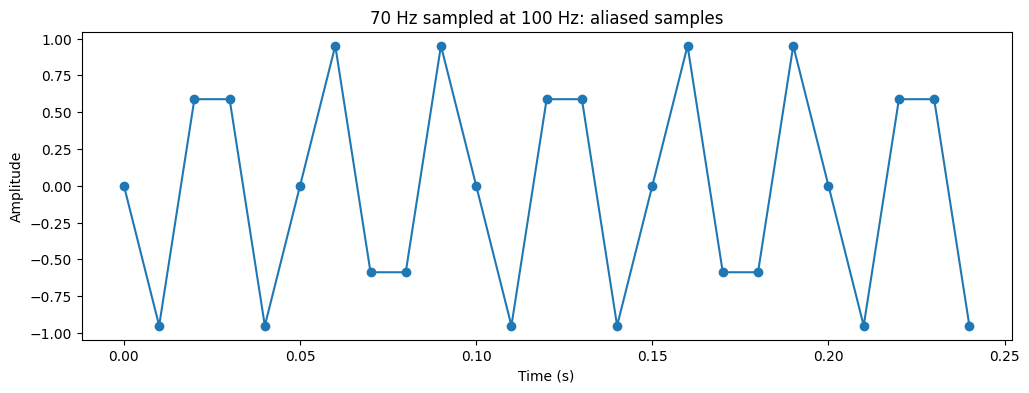

In [49]:
f_true = 70       # Hz
fs_demo = 100     # Hz -> Nyquist = 50 Hz
duration = 0.25

t_demo = np.arange(0, duration, 1/fs_demo)
x_demo = np.sin(2*np.pi*f_true*t_demo)

plt.plot(t_demo, x_demo, "o-")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("70 Hz sampled at 100 Hz: aliased samples")
plt.show()

## Sampling choices depend on the signal and task

Questions to ask:

1. What frequency content contains useful physiology?
2. What sampling rate was used during acquisition?
3. Are we analysing rhythm, morphology, activity, or trends?
4. Will we combine datasets recorded at different sampling rates?

### Example
A rhythm classifier may tolerate resampling more easily than a method relying on subtle ECG morphology.

**Do not resample just because “all models need the same length.”**

## Safe downsampling: anti-alias first

Bad idea:

```python
x_down = x[::4]
```

This simply discards samples and may create aliasing.

Better:

```python
resample_poly(...)
```

It performs filtering as part of rational resampling.

### Rule
**Before reducing sampling rate, suppress frequencies that the new sampling rate cannot represent.**

## Resample a real ECG

Example: MIT-BIH ECG from 360 Hz to 180 Hz.

We keep the **duration** the same while reducing the number of samples.

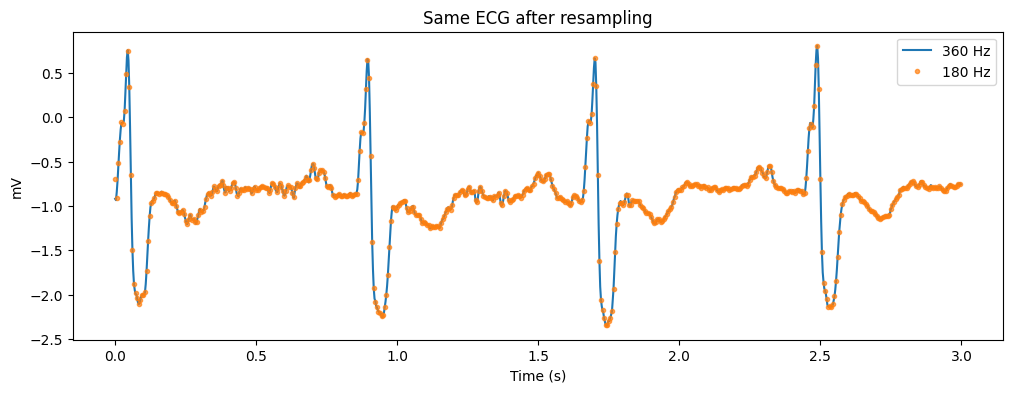

In [10]:
x = clean.p_signal[:, 0]
fs_old = int(clean.fs)
fs_new = 180

x_resampled = resample_poly(x, up=fs_new, down=fs_old)

t_old = np.arange(len(x)) / fs_old
t_new = np.arange(len(x_resampled)) / fs_new

plt.plot(t_old[:3*fs_old], x[:3*fs_old], label=f"{fs_old} Hz")
plt.plot(t_new[:3*fs_new], x_resampled[:3*fs_new],
         ".", alpha=0.7, label=f"{fs_new} Hz")
plt.xlabel("Time (s)")
plt.ylabel(clean.units[0])
plt.legend()
plt.title("Same ECG after resampling")
plt.show()

## What is filtering trying to do?

A filter keeps some frequency components and attenuates others.

Common choices:

- **high-pass**: suppress slow baseline drift;
- **low-pass**: suppress high-frequency noise;
- **band-pass**: keep a chosen frequency range;
- **notch**: suppress a narrow frequency such as mains interference.

But filtering is a scientific choice:

> remove nuisance variation **without destroying useful physiology**.

## High-pass filter: remove slow baseline drift

For ECG, a small high-pass cutoff can reduce slow baseline movement.

Example concept:

- unwanted: very slow baseline drift;
- wanted: most ECG morphology and rhythm information.

The exact cutoff should match the task and accepted domain practice.

In [11]:
def highpass(x, fs, cutoff=0.5, order=4):
    sos = butter(order, cutoff, btype="highpass",
                 fs=fs, output="sos")
    return sosfiltfilt(sos, x)

## Low-pass filter: reduce high-frequency noise

A low-pass filter attenuates frequencies above a cutoff.

For an ECG demonstration we might use a cutoff such as 40 Hz.

That is **not automatically correct for every ECG task**.

If fine morphology or higher-frequency content matters, a lower cutoff may remove information.

In [12]:
def lowpass(x, fs, cutoff=40, order=4):
    sos = butter(order, cutoff, btype="lowpass",
                 fs=fs, output="sos")
    return sosfiltfilt(sos, x)

## Band-pass filter: combine both ideas

A band-pass filter retains a frequency interval.

For an introductory ECG example:

$0.5 \text{ Hz} \rightarrow 40 \text{ Hz}$


This can reduce:

- slow baseline drift;
- some high-frequency noise.

But severe electrode-motion artefact may still remain.

In [13]:
def bandpass(x, fs, low=0.5, high=40, order=4):
    sos = butter(
        order, [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )
    return sosfiltfilt(sos, x)

## Why Butterworth?

A Butterworth filter is common in biomedical examples because its passband is smooth.

In SciPy:

```python
butter(..., output="sos")
```

returns **second-order sections (SOS)**.

Using SOS is generally more numerically stable than using one high-order polynomial filter.

Today we focus on:

- choosing meaningful cutoffs;
- comparing before vs after;
- recognizing that filtering is not magic.

## Zero-phase filtering with `filtfilt` / `sosfiltfilt`

A standard causal filter can shift waveform features in time.

`filtfilt` applies filtering forward and backward.

`sosfiltfilt` does the same idea for SOS filters.

### Benefit
Approximately **zero phase shift**.

### Important limitation
It uses future samples too, so it is appropriate for **offline analysis**, not true real-time deployment.

## Raw vs filtered noisy ECG

Now filter the noisy ECG and compare the waveform.

Do not ask only:

> “Does it look cleaner?”

Also ask:

> “Did I preserve the clinically/physiologically meaningful structure?”

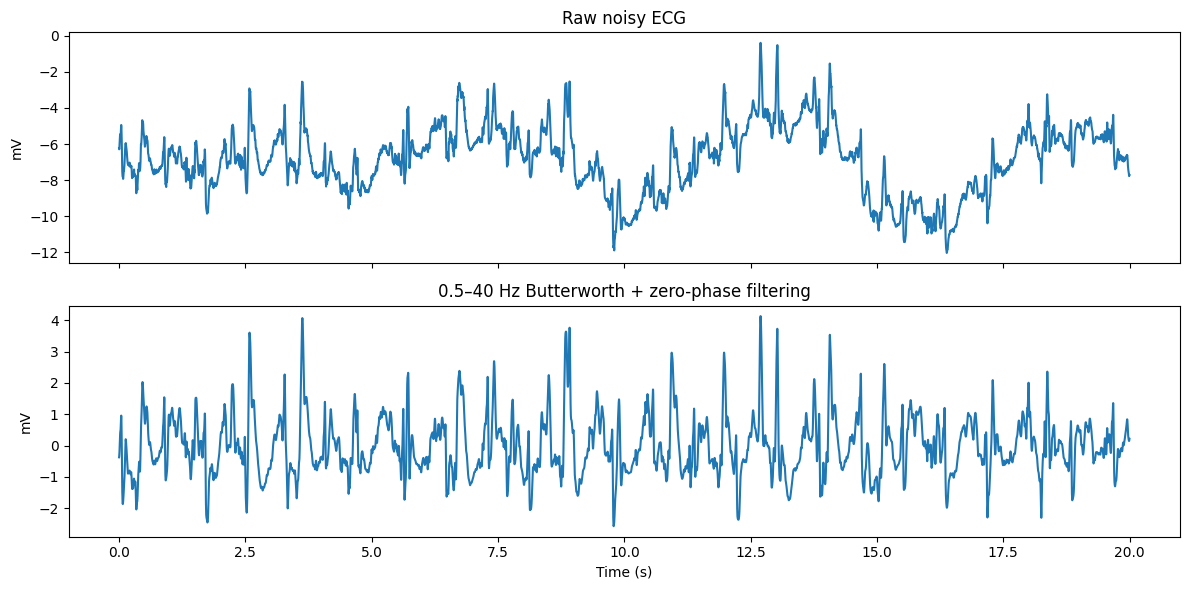

In [14]:
x_noisy = noisy.p_signal[:, 0]
x_filt = bandpass(x_noisy, fs, low=0.5, high=40)

t = np.arange(len(x_noisy)) / fs

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(t, x_noisy)
ax[0].set_title("Raw noisy ECG")
ax[0].set_ylabel(noisy.units[0])

ax[1].plot(t, x_filt)
ax[1].set_title("0.5–40 Hz Butterworth + zero-phase filtering")
ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel(noisy.units[0])

plt.tight_layout()
plt.show()

## Mains interference: notch filter

In Denmark and much of Europe, mains frequency is **50 Hz**.

A notch filter targets a narrow band around that frequency.

For teaching, we add a controlled 50 Hz component to a real ECG and then remove it.

This makes the effect visible without claiming that every PhysioNet ECG contains 50 Hz interference.

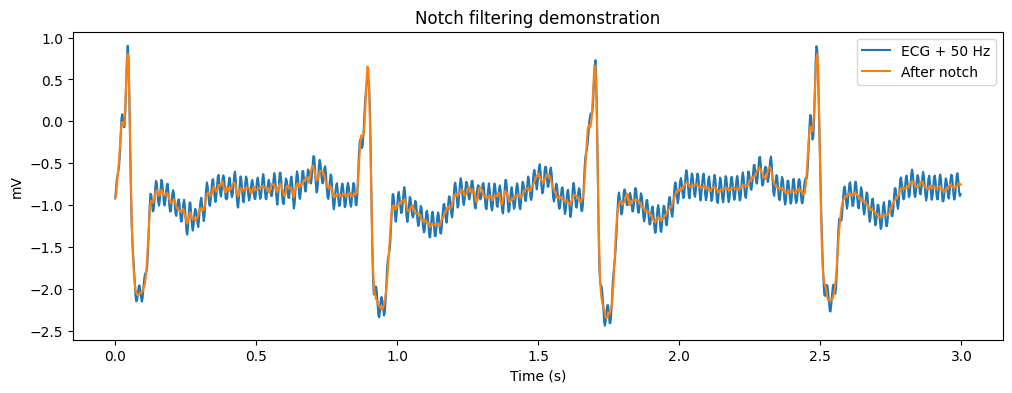

In [15]:
x_real = clean.p_signal[:, 0]
t = np.arange(len(x_real)) / fs

x_50 = x_real + 0.15 * np.sin(2*np.pi*50*t)

b, a = iirnotch(w0=50, Q=30, fs=fs)
x_notched = filtfilt(b, a, x_50)

plt.plot(t[:3*int(fs)], x_50[:3*int(fs)], label="ECG + 50 Hz")
plt.plot(t[:3*int(fs)], x_notched[:3*int(fs)], label="After notch")
plt.xlabel("Time (s)")
plt.ylabel(clean.units[0])
plt.legend()
plt.title("Notch filtering demonstration")
plt.show()

## Filtering can also make data worse

Possible problems:

- too-high high-pass cutoff → distorted ST/T morphology;
- too-low low-pass cutoff → smoothed QRS complexes;
- aggressive filtering → lost physiological information;
- filtering a flatline → still a flatline;
- motion artefact can overlap the physiological frequency range;
- edge effects may appear near segment boundaries.

### Good practice
1. justify the cutoff;
2. plot before/after;
3. keep the raw data unchanged;
4. document preprocessing parameters.

## Why segment a long recording?

Many analyses operate on shorter pieces:

- 5–10 s ECG classification;
- 30 s sleep epochs;
- activity windows from accelerometers;
- beat-centred ECG morphology;
- pulse-centred PPG analysis.

Segmentation gives us:

- consistent units of analysis;
- local quality assessment;
- inputs for feature extraction;
- manageable model inputs.

## Convert seconds to samples

If a window is \(T\) seconds:

$N_\mathrm{window} = T \times f_s$


Example:

- 10 s window
- 360 Hz ECG
- (10 $\times$ 360 = 3600) samples

Never hard-code sample counts without considering `fs`.

In [16]:
window_s = 10
window_samples = int(window_s * fs)

print("Window length:", window_samples, "samples")

Window length: 3600 samples


## Fixed non-overlapping windows

Example: 30 seconds of data → three 10-second windows.

Useful when:

- independent chunks are sufficient;
- simple interpretation matters;
- you want to reduce redundancy.

A final incomplete window can be:

- discarded;
- padded;
- handled separately.

Choose deliberately.

In [17]:
def fixed_windows(x, fs, window_s):
    n = int(window_s * fs)

    return [
        x[start:start+n]
        for start in range(0, len(x) - n + 1, n)
    ]

windows = fixed_windows(x_noisy, fs, window_s=5)
print("Number of windows:", len(windows))
print("Samples per window:", len(windows[0]))

Number of windows: 4
Samples per window: 1800


## Overlapping windows

With overlap, adjacent windows share samples.

Example:

- window length = 10 s
- overlap = 50%
- step = 5 s

Benefits:

- more temporal coverage;
- events near one boundary can appear centrally in another window.

Cost:

- windows are more correlated;
- more computation;
- **data leakage risk** if windows from one participant are split across train/test later.

## A reusable window function

Return both:

- the window samples;
- the window start time.

Keeping timing information makes later plots and quality checks much easier.

In [18]:
def make_windows(x, fs, window_s=10, overlap=0.5):
    n = int(window_s * fs)
    step = int(n * (1 - overlap))

    if step <= 0:
        raise ValueError("overlap must be < 1")

    result = []

    for start in range(0, len(x) - n + 1, step):
        result.append({
            "start_s": start / fs,
            "signal": x[start:start+n]
        })

    return result

segments = make_windows(x_noisy, fs, window_s=5, overlap=0.5)
print("Created", len(segments), "segments")

Created 7 segments


## Event-based segmentation

Not every useful window starts at a fixed clock time.

Examples:

- ECG around an annotated beat;
- EEG around a stimulus;
- PPG around a detected pulse;
- accelerometry around a detected activity event.

For an ECG beat at sample \(s\), we might keep:

- 0.30 s before;
- 0.50 s after.

Event-based windows are aligned to physiology rather than arbitrary time boundaries.

In [19]:
# Example concept using MIT-BIH annotations
record_name = "101"
segment_start_s = 0
segment_end_s = 20

hdr101 = wfdb.rdheader(record_name, pn_dir="mitdb")
fs101 = hdr101.fs

ann = wfdb.rdann(
    record_name, "atr", pn_dir="mitdb",
    sampfrom=int(segment_start_s * fs101),
    sampto=int(segment_end_s * fs101)
)

pre = int(0.30 * fs101)
post = int(0.50 * fs101)

print("First annotation samples:", ann.sample[:5])
print("Event window:", pre, "samples before and", post, "after")

First annotation samples: [   7   83  396  711 1032]
Event window: 108 samples before and 180 after


## Put the pieces into a preprocessing function

A reproducible function should make choices explicit.

Possible steps:

1. check missing values;
2. optionally resample;
3. optionally filter;
4. segment;
5. compute window-level quality;
6. retain both data and metadata.

**Do not silently preprocess.**  
Parameters belong in code, documentation, and eventually the manuscript/report.

In [20]:
def preprocess_ecg(
    x, fs,
    low=0.5, high=40,
    window_s=10, overlap=0.5
):
    x = np.asarray(x, dtype=float)

    # Filter
    x_clean = bandpass(x, fs, low=low, high=high)

    # Segment
    segments = make_windows(
        x_clean, fs,
        window_s=window_s,
        overlap=overlap
    )

    # Add simple QC
    for seg in segments:
        seg["quality"] = basic_quality_metrics(seg["signal"])

    return segments

## Exercise 1 — Filter a real noisy ECG (30 min)

Use **NSTDB `118e00`**, during the noisy period after 5 minutes.

### Tasks
1. load 20 s of channel 0 starting at 305 s;
2. plot the raw waveform;
3. apply a 0.5–40 Hz band-pass filter;
4. plot raw and filtered signals;
5. calculate the basic quality metrics for both;
6. write **three observations**:
   - what improved?
   - what remained problematic?
   - could filtering have removed useful information?

Starter code is provided in the exercise notebook.

### Exercise 1 — Starter code

Use the cells below as your starting point.

Complete the `TODO` items and add your observations beneath the plots.

In [21]:
# Exercise 1 starter code
record_name = "118e00"
pn_dir = "nstdb"

start_s = 305
duration_s = 20

header = wfdb.rdheader(record_name, pn_dir=pn_dir)
fs_ex1 = header.fs

sampfrom = int(start_s * fs_ex1)
sampto = int((start_s + duration_s) * fs_ex1)

record_ex1 = wfdb.rdrecord(
    record_name,
    pn_dir=pn_dir,
    sampfrom=sampfrom,
    sampto=sampto
)

x_ex1 = record_ex1.p_signal[:, 0]
t_ex1 = np.arange(len(x_ex1)) / fs_ex1

print("Sampling frequency:", fs_ex1)
print("Channels:", record_ex1.sig_name)
print("Units:", record_ex1.units)
print("Segment shape:", record_ex1.p_signal.shape)

Sampling frequency: 360
Channels: ['MLII', 'V1']
Units: ['mV', 'mV']
Segment shape: (7200, 2)


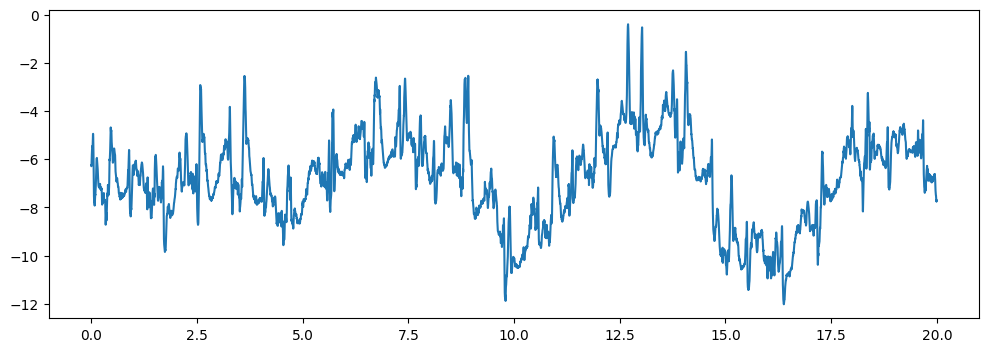

In [22]:
# Task 2 — Plot the raw ECG

plt.plot(t_ex1, x_ex1)

# TODO: add a title
# TODO: label the x-axis
# TODO: label the y-axis using record_ex1.units[0]

plt.show()

In [23]:
# Task 3 — Filter the ECG

# TODO: apply the 0.5–40 Hz band-pass filter
x_filtered_ex1 = None

# Hint:
# x_filtered_ex1 = bandpass(
#     x_ex1, fs_ex1,
#     low=0.5, high=40
# )

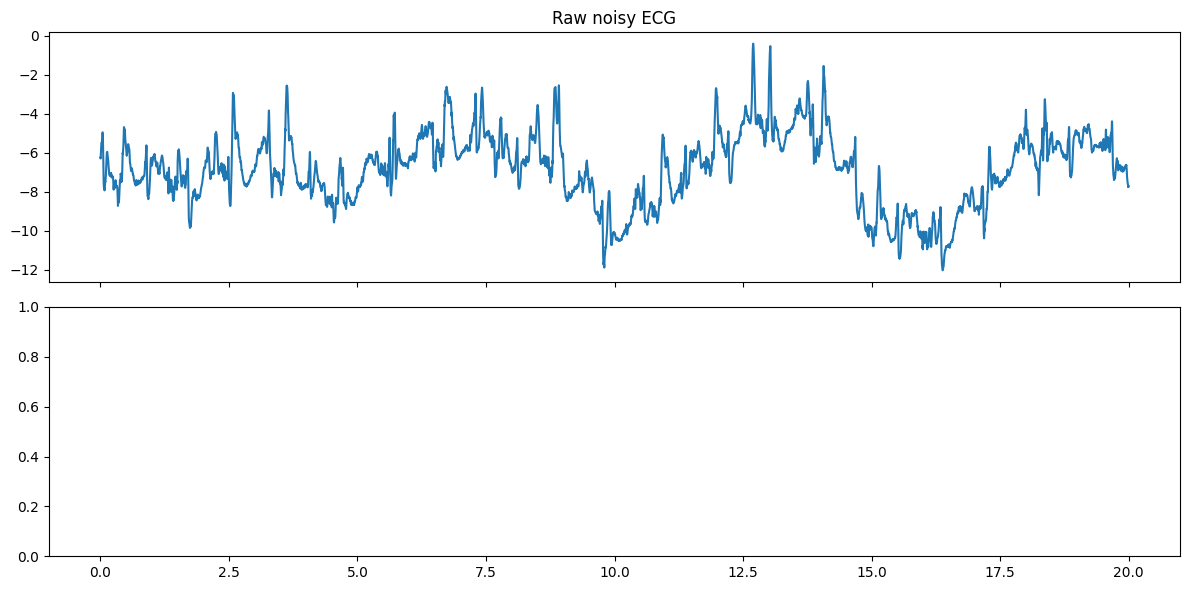

In [24]:
# Task 4 — Compare raw and filtered signals

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

ax[0].plot(t_ex1, x_ex1)
ax[0].set_title("Raw noisy ECG")

# TODO: plot x_filtered_ex1 on ax[1]
# TODO: add a descriptive title
# TODO: label the axes

plt.tight_layout()
plt.show()

In [25]:
# Task 5 — Compare simple quality metrics

# TODO: calculate metrics for the raw signal
raw_metrics = None

# TODO: calculate metrics for the filtered signal
filtered_metrics = None

# TODO: build a two-row DataFrame
quality_comparison = None

quality_comparison

**Interpretation — write three short observations**

1. What visibly improved after filtering?
2. What artefact or noise remained?
3. Could the filter have removed useful physiological information?

## Exercise 2 — Multimodal segmentation (30 min)

Use **Challenge 2015 `a103l`**.

### Tasks
1. load the first 60 s;
2. inspect `sig_name`, units, and `fs`;
3. choose one ECG-like channel and `PLETH` if available;
4. create 10 s windows with 50% overlap;
5. calculate simple quality metrics per window;
6. plot one window from each selected channel;
7. discuss:
   - should ECG and PLETH use identical preprocessing?
   - which quality metrics are meaningful for each?

### Project connection
How would you adapt this workflow to your chosen PhysioNet dataset?

### Exercise 2 — Starter code

Use the cells below to inspect the multimodal record, choose channels, create overlapping windows, and compare window-level quality.

In [26]:
# Exercise 2 starter code
record_name = "a103l"
pn_dir = "challenge-2015/training"

header_ex2 = wfdb.rdheader(record_name, pn_dir=pn_dir)
fs_ex2 = header_ex2.fs

record_ex2 = wfdb.rdrecord(
    record_name,
    pn_dir=pn_dir,
    sampfrom=0,
    sampto=int(60 * fs_ex2)
)

print("Sampling frequency:", fs_ex2)
print("Channels:", record_ex2.sig_name)
print("Units:", record_ex2.units)
print("Shape:", record_ex2.p_signal.shape)

Sampling frequency: 250
Channels: ['II', 'V', 'PLETH']
Units: ['mV', 'mV', 'NU']
Shape: (15000, 3)


In [27]:
# Task 2 — Choose ECG and PLETH channels

# TODO: inspect record_ex2.sig_name and enter the correct indices
ecg_idx = None
pleth_idx = None

# After entering the indices, uncomment:
# ecg_ex2 = record_ex2.p_signal[:, ecg_idx]
# pleth_ex2 = record_ex2.p_signal[:, pleth_idx]

In [28]:
# Task 3 — Plot the first 20 seconds

# TODO: uncomment after selecting channels

# t_ex2 = np.arange(record_ex2.sig_len) / fs_ex2

# fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# ax[0].plot(
#     t_ex2[:int(20 * fs_ex2)],
#     ecg_ex2[:int(20 * fs_ex2)]
# )
# ax[0].set_title(record_ex2.sig_name[ecg_idx])

# ax[1].plot(
#     t_ex2[:int(20 * fs_ex2)],
#     pleth_ex2[:int(20 * fs_ex2)]
# )
# ax[1].set_title(record_ex2.sig_name[pleth_idx])
# ax[1].set_xlabel("Time (s)")

# plt.tight_layout()
# plt.show()

In [29]:
# Task 4 — Create 10 s windows with 50% overlap

# TODO: uncomment after selecting channels

# ecg_windows = make_windows(
#     ecg_ex2, fs_ex2,
#     window_s=10,
#     overlap=0.5
# )

# pleth_windows = make_windows(
#     pleth_ex2, fs_ex2,
#     window_s=10,
#     overlap=0.5
# )

# print("ECG windows:", len(ecg_windows))
# print("PLETH windows:", len(pleth_windows))

In [30]:
# Task 5 — Build a window-level quality table

def quality_table(windows, channel_name):
    rows = []

    for w in windows:
        metrics = basic_quality_metrics(w["signal"])
        metrics["start_s"] = w["start_s"]
        metrics["channel"] = channel_name
        rows.append(metrics)

    return pd.DataFrame(rows)


# TODO: uncomment after creating the windows

# q_ecg = quality_table(
#     ecg_windows,
#     record_ex2.sig_name[ecg_idx]
# )

# q_pleth = quality_table(
#     pleth_windows,
#     record_ex2.sig_name[pleth_idx]
# )

# q_all = pd.concat(
#     [q_ecg, q_pleth],
#     ignore_index=True
# )

# q_all

In [31]:
# Task 6 — Inspect one window from each signal

window_idx = 0

# TODO:
# plot ecg_windows[window_idx]["signal"]
# plot pleth_windows[window_idx]["signal"]
# include the window start time in each title

**Interpretation and project connection**

Answer briefly:

1. Should ECG and PLETH automatically use the same filter cutoffs?
2. Which quality metrics were most informative for ECG?
3. Were the same metrics equally meaningful for PLETH?
4. What window length would make sense for your semester-project dataset?
5. What preprocessing details should be documented in the repository?

## Take-home checklist

Before extracting features from a biosignal, ask:

- **What signal and units do I have?**
- **What is the sampling frequency?**
- **Is the waveform physiologically plausible?**
- **Are there artefacts, missing values, clipping, or flat periods?**
- **Do I really need filtering?**
- **Are my cutoff frequencies justified?**
- **Am I resampling safely?**
- **What window length and overlap fit the task?**
- **Can preprocessing create leakage or distort physiology?**
- **Have I documented every preprocessing choice?**


# Thank you!